# 03 — Causal inference

Does more solar *cause* a steeper evening ramp, or do zones with steep ramps simply have more solar? I draw a DAG, derive the admissible adjustment set from it, and compare three designs: a naive regression, difference-in-differences and propensity matching. This runs before modelling so the DAG can inform feature choice.

**Inputs:** `panel.parquet`

**Outputs:** ledger block `results.json:nb03`; `docs/adjustment_set.md`; figures `03_dag.png`, `03_did.png`, `03_matching.png`.


### 3.1 — Setup

Load the panel and build one row per complete local zone-day. The outcome is the evening ramp: the range (max − min) of net load over local hours 16–21. The treatment is the day's solar output over demand.


In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as cfg
from src import results as R

pd.set_option("display.width", 140, "display.max_columns", 50)
plt.rcParams["figure.figsize"] = cfg.FIGSIZE
plt.rcParams["figure.dpi"] = cfg.DPI
np.random.seed(cfg.SEED)

df = pd.read_parquet(cfg.PANEL)
# LOCAL CLOCK, PER ZONE. The panel is stored in UTC, and hours 16-21 of the UTC
# timestamp are 08:00-13:00 in California and 11:00-16:00 in New York in standard time
# (09:00-14:00 and 12:00-17:00 in summer time): the midday solar ramp-down, not the
# evening ramp. The evening window and the day itself are therefore
# taken on each zone's own clock (cfg.ZONE_TZ), as notebooks 00 and 05 do.
_local = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
for _zone, _tz in cfg.ZONE_TZ.items():
    _m = (df[cfg.GROUP_COL] == _zone).to_numpy()
    _local[_m] = (df.loc[_m, cfg.TIME_COL].dt.tz_localize("UTC")
                  .dt.tz_convert(_tz).dt.tz_localize(None))
df['date'] = _local.dt.date
df['hour'] = _local.dt.hour

evening = df[df['hour'].between(16, 21)]
daily = (df.groupby([cfg.GROUP_COL, 'date'])
           .agg(solar_share=('solar', 'sum'), demand=('demand', 'sum'),
                temp=('temp', 'mean'), humidity=('humidity', 'mean'),
                wind_speed=('wind_speed', 'mean'), cloud_cover=('cloud_cover', 'mean'),
                n_hours=('solar', 'size'))
           .assign(solar_share=lambda d: d['solar_share'] / d['demand']))
# Only complete local days (23 or 25 hours on the DST switch days); the first and last
# local day of each zone are partial because the panel starts and ends on UTC midnight.
daily = daily[daily['n_hours'] >= 23].drop(columns='n_hours')
daily['evening_ramp'] = (evening.groupby([cfg.GROUP_COL, 'date'])[cfg.TARGET]
                                .apply(lambda s: s.max() - s.min()))
daily = daily.reset_index().dropna()
daily['date'] = pd.to_datetime(daily['date'])
display(daily.head())

,zone,date,solar_share,demand,temp,humidity,wind_speed,cloud_cover,evening_ramp
0,BPAT,2019-01-01,0.000080,175799.0,0.750000,82.583333,4.458333,55.625000,970.0
1,BPAT,2019-01-02,0.000099,181917.0,1.750000,83.666667,4.604167,89.166667,681.0
2,BPAT,2019-01-03,0.000042,166094.0,7.904167,74.583333,17.170833,99.583333,530.0
3,BPAT,2019-01-04,0.000031,159689.0,7.370833,86.791667,12.729167,97.875000,663.0
4,BPAT,2019-01-05,0.000031,160020.0,6.287500,81.166667,15.500000,97.458333,925.0


### 3.2 — The DAG and its adjustment set

The causal graph is an edge list in `src/causal.py`. The figure, the backdoor enumeration, the adjustment set and `docs/adjustment_set.md` all come from that one object, so they cannot disagree. The edge list is an assumption, not a finding; each edge carries its reason in the source.

Weather is upstream of the power system and caused by none of it. `temp`, `humidity` and `wind_speed` drive demand; `cloud_cover` and `temp` drive solar output.

Panel (a) is the graph with nothing adjusted; panel (b) marks the minimal admissible set. Red outlines are unmeasured nodes; yellow nodes are colliders.

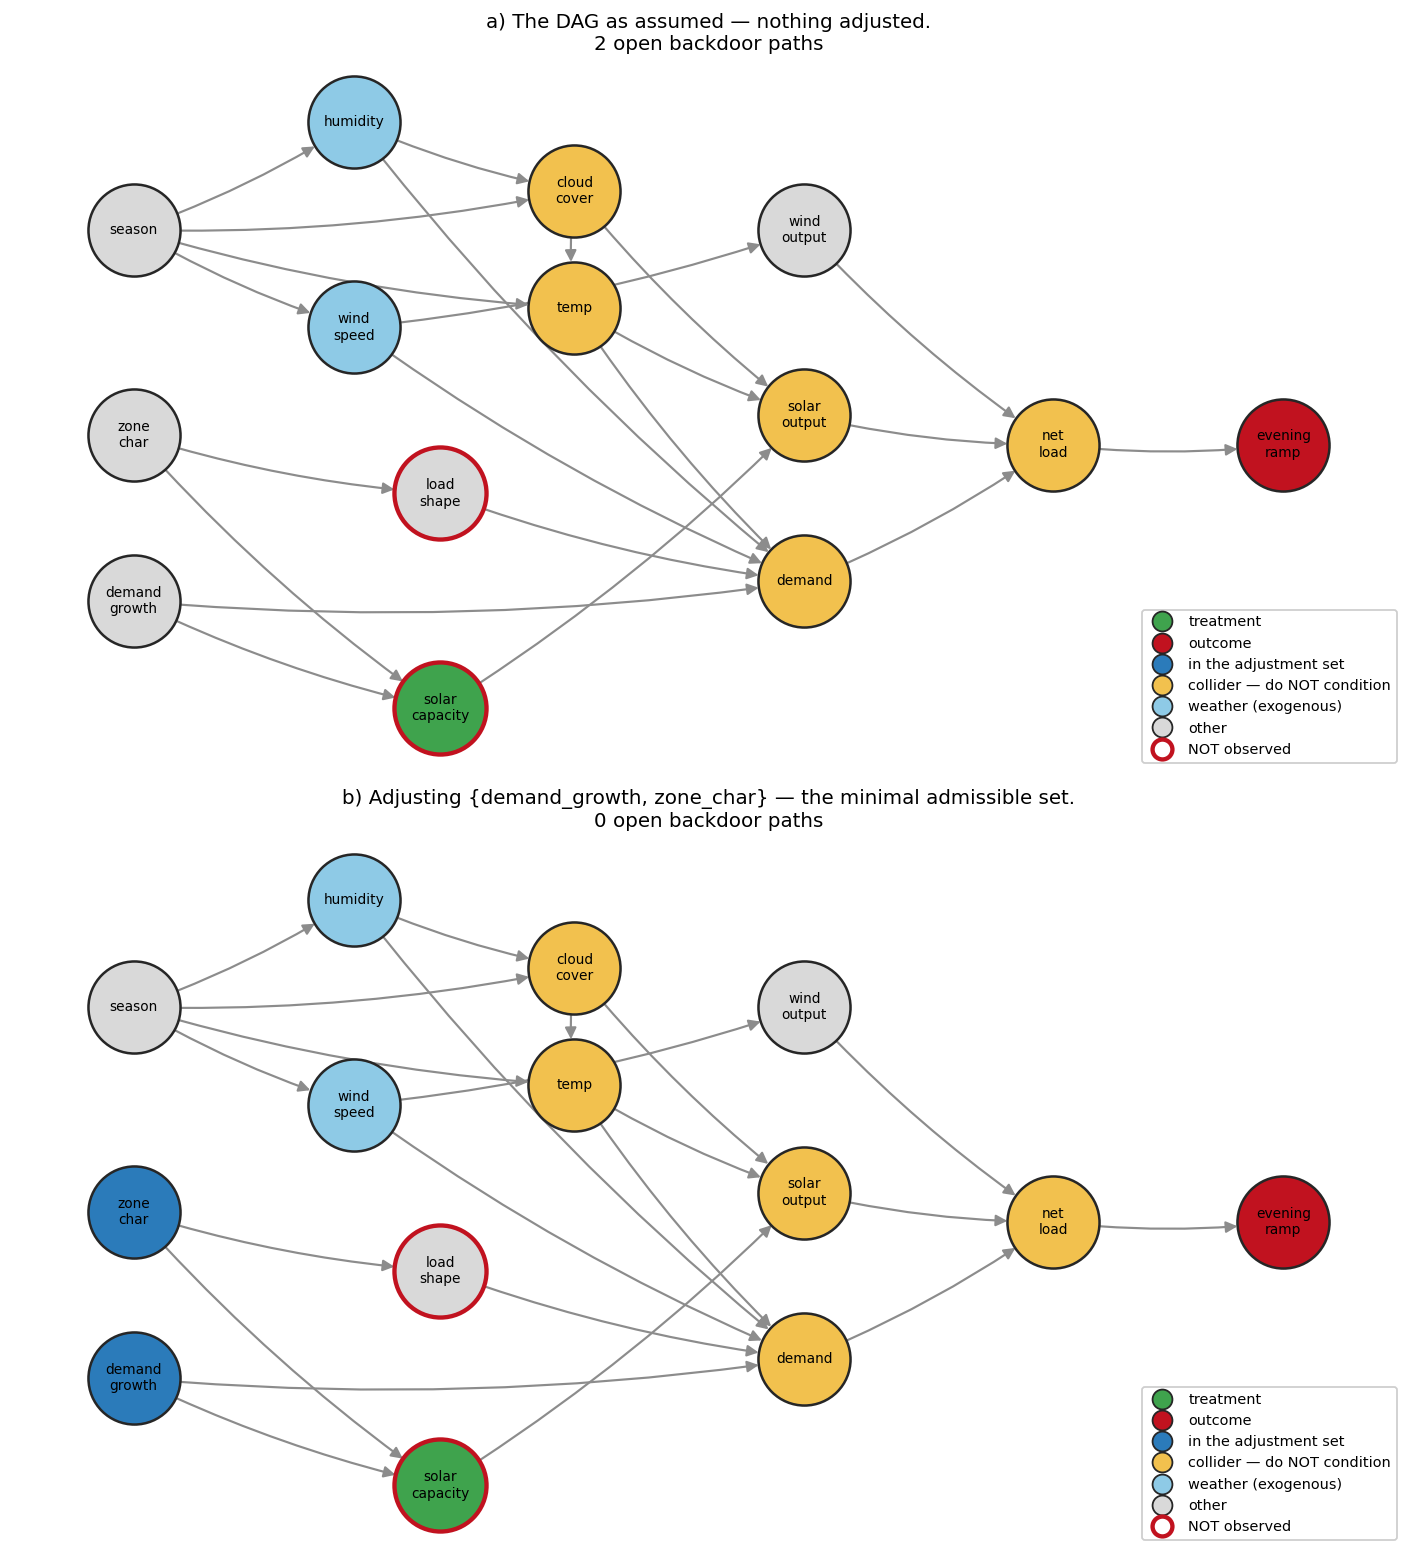

treatment = solar_capacity   outcome = evening_ramp
colliders in the graph: ['cloud_cover', 'demand', 'net_load', 'solar_capacity', 'solar_output', 'temp']

total backdoor paths: 56. OPEN with nothing adjusted:
  [OPEN   ] solar_capacity  ->  demand_growth  ->  demand  ->  net_load  ->  evening_ramp
  [OPEN   ] solar_capacity  ->  zone_char  ->  load_shape  ->  demand  ->  net_load  ->  evening_ramp

--- what conditioning does to the number of OPEN backdoor paths ---
  adjust {}                                           open=  2  admissible=False
  adjust {zone_char}                                  open=  1  admissible=False
  adjust {demand}                                     open= 48  admissible=False
  adjust {demand, season, temp}                       open=  4  admissible=False
  adjust {demand_growth, zone_char}                   open=  0  admissible=True

The PLAN's proposed matching set is {temperature, season, day of week,
demand level}. Under this DAG it is NOT admissible. 


minimal admissible adjustment sets over OBSERVED nodes:
   {demand_growth, zone_char}
   {cloud_cover, demand, temp, wind_output}
   {cloud_cover, demand, temp, wind_speed}
   {demand, humidity, temp, wind_speed}

wrote docs/adjustment_set.md (60 lines)
[results read-only] nb03: 8 key(s) verified against the ledger, nothing written


In [2]:
# WHAT: build the DAG, draw it, enumerate backdoor paths, and derive the adjustment
#       set by the backdoor criterion. Then write docs/adjustment_set.md from the
#       same object so the document cannot drift from the computation.
# WHY:  the adjustment set is the deliverable that makes the notebook ordering pay --
#       it is an INPUT to notebook 04's feature choice, not a postscript to it.
# NOTE: src/causal.py implements the three structures (chain, fork, collider) and is
#       tested in tests/test_causal.py against textbook graphs AND against
#       networkx's independent d-separation. Two implementations, one answer.
from src import causal as C

g = C.build_dag()
Z_MIN = {"zone_char", "demand_growth"}

fig, axes = plt.subplots(2, 1, figsize=(11.0, 12.1))
C.draw_dag(axes[0], g, adjust=set())
axes[0].set_title("a) The DAG as assumed — nothing adjusted.\n"
                  f"{len(C.open_backdoor_paths(g, set()))} open backdoor paths", fontsize=11)
C.draw_dag(axes[1], g, adjust=Z_MIN)
axes[1].set_title(f"b) Adjusting {{{', '.join(sorted(Z_MIN))}}} — the minimal admissible set.\n"
                  f"{len(C.open_backdoor_paths(g, Z_MIN))} open backdoor paths", fontsize=11)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "03_dag.png", bbox_inches="tight")
plt.show()

n_back = len(C.backdoor_paths(g))
print(f"treatment = {C.TREATMENT}   outcome = {C.OUTCOME}")
print(f"colliders in the graph: {C.colliders_in(g)}")
print(f"\ntotal backdoor paths: {n_back}. OPEN with nothing adjusted:")
print(C.describe_paths(g, C.open_backdoor_paths(g, set())))

# --- the collider demonstration, which is the point of the whole section --------
print("\n--- what conditioning does to the number of OPEN backdoor paths ---")
trials = [set(), {"zone_char"}, {"demand"}, {"temp", "season", "demand"}, Z_MIN]
for z in trials:
    n_open = len(C.open_backdoor_paths(g, z))
    ok = C.is_valid_adjustment_set(g, z)
    label = "{}" if not z else "{" + ", ".join(sorted(z)) + "}"
    print(f"  adjust {label:44s} open={n_open:3d}  admissible={ok}")

print("\nThe PLAN's proposed matching set is {temperature, season, day of week,")
print("demand level}. Under this DAG it is NOT admissible. Paths it leaves open:")
plan_set = {"temp", "season", "demand"}
print(C.describe_paths(g, C.open_backdoor_paths(g, plan_set), plan_set))

# --- admissible sets ------------------------------------------------------------
sets_obs = C.minimal_adjustment_sets(g, observed_only=True)
print("\nminimal admissible adjustment sets over OBSERVED nodes:")
for z in sets_obs:
    print("   {" + ", ".join(sorted(z)) + "}")

# --- write the deliverable doc --------------------------------------------------
doc = ["# 05 — The adjustment set implied by the DAG",
       "", "## The graph", "", "| parent | child | why this edge is claimed |", "|---|---|---|"]
for u, v, d in sorted(g.edges(data=True)):
    doc.append(f"| `{u}` | `{v}` | {d['why']} |")
doc += ["", "## Backdoor paths", "",
        f"- total backdoor paths: **{n_back}**",
        f"- open with nothing adjusted: **{len(C.open_backdoor_paths(g, set()))}**",
        f"- colliders in the graph: {', '.join('`'+c+'`' for c in C.colliders_in(g))}",
        "", "## Admissible adjustment sets (observed nodes only)", ""]
for z in sets_obs:
    doc.append(f"- {{ {', '.join('`'+n+'`' for n in sorted(z))} }}")
doc += ["", "## What is NOT admissible, and why", "",
        "| set | admissible | reason |", "|---|---|---|",
        f"| {{ `demand` }} | **no** | `demand` is a collider "
        f"(parents: {', '.join(sorted(g.predecessors('demand')))}). Conditioning on it "
        f"opens {len(C.open_backdoor_paths(g, {'demand'}))} backdoor paths, against "
        f"{len(C.open_backdoor_paths(g, set()))} when nothing is adjusted. |",
        "| { `temp`, `season`, `demand` } | **no** | the set the project plan proposes "
        "for propensity matching. It conditions on the `demand` collider without "
        "blocking the paths that opens. |",
        f"| {{ `net_load` }} | **no** | `net_load` is both a descendant of the treatment "
        "and the collider of the accounting identity `net_load = demand − wind − solar`. |",
        "", "## Where notebook 04's predictive feature set departs from this, deliberately", "",
        "notebook 04 regresses **on** `net_load` and uses `demand`-derived history, both of "
        "which are inadmissible here. That is not an inconsistency: the two notebooks have "
        "different targets. Prediction estimates `E[y | features]`, where any variable "
        "carrying information is admissible and a collider is simply a useful covariate. "
        "Causal identification estimates an effect, where conditioning on a collider "
        "opens a non-causal path. Same data, different estimand, different admissible "
        "set.", "",
        "## The three assumptions this rests on", "",
        "1. **Parallel trends** — treated and control zones would have moved together "
        "absent the treatment. Checked as a plot in 3.4; believed or not on the evidence "
        "there.", "2. **No unmeasured confounding** — the graph above is complete. This "
        "is unverifiable from data; 3.5 reports how strong an omitted cause would have "
        "to be to overturn the estimate.",
        "3. **Positivity** — every covariate stratum contains both treated and control "
        "units. Checked by the overlap plot in 3.5.", ""]
(cfg.ROOT / "docs" / "adjustment_set.md").write_text("\n".join(doc), encoding="utf-8")
print(f"\nwrote docs/adjustment_set.md ({len(doc)} lines)")

R.save("nb03", {
    "dag_edges": [[u, v] for u, v, _ in g.edges(data=True)],
    "colliders": C.colliders_in(g),
    "n_backdoor_paths": int(n_back),
    "n_open_unadjusted": int(len(C.open_backdoor_paths(g, set()))),
    "n_open_given_demand": int(len(C.open_backdoor_paths(g, {"demand"}))),
    "plan_set_admissible": bool(C.is_valid_adjustment_set(g, plan_set)),
    "adjustment_sets_observed": [sorted(z) for z in sets_obs],
    "adjustment_set_used": sorted(Z_MIN),
});

**Figure: `03_dag.png`.** With nothing adjusted, 2 of 56 backdoor paths are open. Conditioning on `demand_growth` and `zone_char` closes both. A backdoor path is a non-causal route by which solar and the evening ramp could move together.

**What this shows:** The assumed causal graph. Green is the treatment, dark red the outcome, yellow the colliders, light blue the weather, and a red ring marks a variable not in the data.

**What I see:** Adjusting for `demand_growth` and `zone_char` closes both open paths. Conditioning on `demand` alone opens 48 of the 56, because `demand` is a collider: temperature, humidity, wind speed, load shape and demand growth all point into it. The treatment node, `solar capacity`, is not observed, and neither is `load shape`. The plan's proposed adjustment set is not admissible.

**What it means:** Controlling for a collider creates bias instead of removing it, so "control for everything" is wrong here. Since solar capacity is unobserved, the sections below compare high-solar-output days with low-solar-output days; they cannot say what building more solar would do.

**What I do:** Choose matching covariates from the DAG (§3.5; this changes the answer by 1,537 MW), never condition on `demand` alone, and state the capacity-versus-output gap wherever the estimates appear.

### 3.3 — The naive association

Regress evening ramp on solar share with no adjustment. This is the baseline the rest of the notebook corrects. The coefficient is a slope per percentage point, a different estimand from the MW effects below, so the designs are compared by sign, size and interval width, not subtracted.


In [3]:
# WHAT: the unadjusted regression of evening ramp on solar share, with a standard
#       error, and the coefficient stated in BOTH units.
# WHY:  this is the number a careless analysis reports. It is a per-percentage-point
#       slope, not the same estimand as the DiD or matched effects, so the finding is
#       how differently the designs answer, not a subtraction.
# THE UNIT TRAP, STATED ONCE AND LOUDLY. `solar_share` is a fraction in [0, 1], so
# a coefficient "per unit solar share" is per 100 percentage points. The archived
# 08-14 block held BOTH `naive_coef: 14,950.5` and `naive_coef_mw_per_pp: 583.3`
# -- a factor of ~26 apart -- and a previous session lost time trying to reproduce
# the second from the first. They are different quantities from different frames.
# This cell prints both, derived from one fit, so the pair can never drift again.
import statsmodels.api as sm

Xn = sm.add_constant(daily[["solar_share"]].to_numpy())
fit_naive = sm.OLS(daily["evening_ramp"].to_numpy(), Xn).fit(
    cov_type="cluster", cov_kwds={"groups": daily[cfg.GROUP_COL].to_numpy()},
    use_t=True)   # t with (clusters - 1) degrees of freedom: six clusters, not a normal
naive = float(fit_naive.params[1])
naive_se = float(fit_naive.bse[1])
naive_ci = [float(v) for v in fit_naive.conf_int()[1]]

print(f"naive coefficient: {naive:,.1f} MW per UNIT solar share")
print(f"                 = {naive / 100:,.1f} MW per PERCENTAGE POINT")
print(f"cluster-robust SE {naive_se:,.1f} (6 zone clusters), "
      f"95% CI [{naive_ci[0]:,.0f}, {naive_ci[1]:,.0f}] per unit")
print(f"n = {len(daily):,} zone-days, R^2 = {fit_naive.rsquared:.4f}")
print("\nSIX CLUSTERS IS NOT ENOUGH FOR CLUSTER-ROBUST INFERENCE. The rule of thumb "
      "is ~40; the interval above is reported because omitting it would be worse, "
      "but it is not to be read as a 95% interval.")

naive coefficient: 58,209.3 MW per UNIT solar share
                 = 582.1 MW per PERCENTAGE POINT
cluster-robust SE 5,776.4 (6 zone clusters), 95% CI [43,361, 73,058] per unit
n = 13,135 zone-days, R^2 = 0.6164

SIX CLUSTERS IS NOT ENOUGH FOR CLUSTER-ROBUST INFERENCE. The rule of thumb is ~40; the interval above is reported because omitting it would be worse, but it is not to be read as a 95% interval.


### 3.4 — Difference-in-differences

The zones whose solar share grew most are treated, the rest are control, before and after a fixed date. DiD removes fixed zone differences and shocks common to both groups, but not shocks that hit them differently, so the pre-period plot is read first.

solar-share growth by zone (first year -> last):
year    2019    2024  growth
zone                        
BPAT  0.0002  0.0048  0.0046
CISO  0.1300  0.2009  0.0709
ERCO  0.0105  0.1020  0.0915
MISO  0.0009  0.0225  0.0216
NYIS  0.0000  0.0000  0.0000
SWPP  0.0020  0.0042  0.0021

treated (above median growth): ['CISO', 'ERCO', 'MISO']
control                       : ['BPAT', 'NYIS', 'SWPP']

t0 = 2022-01-01
  treated  pre      -0.0  post   2,288.7  delta  +2,288.7
  control  pre      -0.0  post     205.0  delta    +205.0
  DiD = +2,083.8 MW
  regression DiD +2,083.8 MW, clustered SE 1,144.0, 95% CI [-857, 5,024]



pre-period quarterly trend: treated +58.9 MW/quarter, control +32.8; divergence 26.1 MW/quarter
pre-trend screen (slope divergence per quarter < 10% of the DiD estimate) passed: True

quarterly means of the deseasonalised ramp (MW; 0 = first quarter after t0, 9 pools quarters 9-11):
     control  treated
rel                  
-12    -90.0   -372.0
-11   -242.0   -538.0
-10    -13.0    362.0
-9    -384.0   -418.0
-8      -1.0   -171.0
-7      96.0    122.0
-6      -1.0    -68.0
-5     193.0    -51.0
-4      91.0    546.0
-3     146.0    416.0
-2      14.0   -293.0
-1     192.0    469.0
 0     248.0   2023.0
 1     394.0    692.0
 2     372.0    -67.0
 3     130.0   1722.0
 4      71.0   1669.0
 5     269.0   1483.0
 6     213.0    892.0
 7     109.0   3895.0
 8     -58.0   4432.0
 9     236.0   3580.0


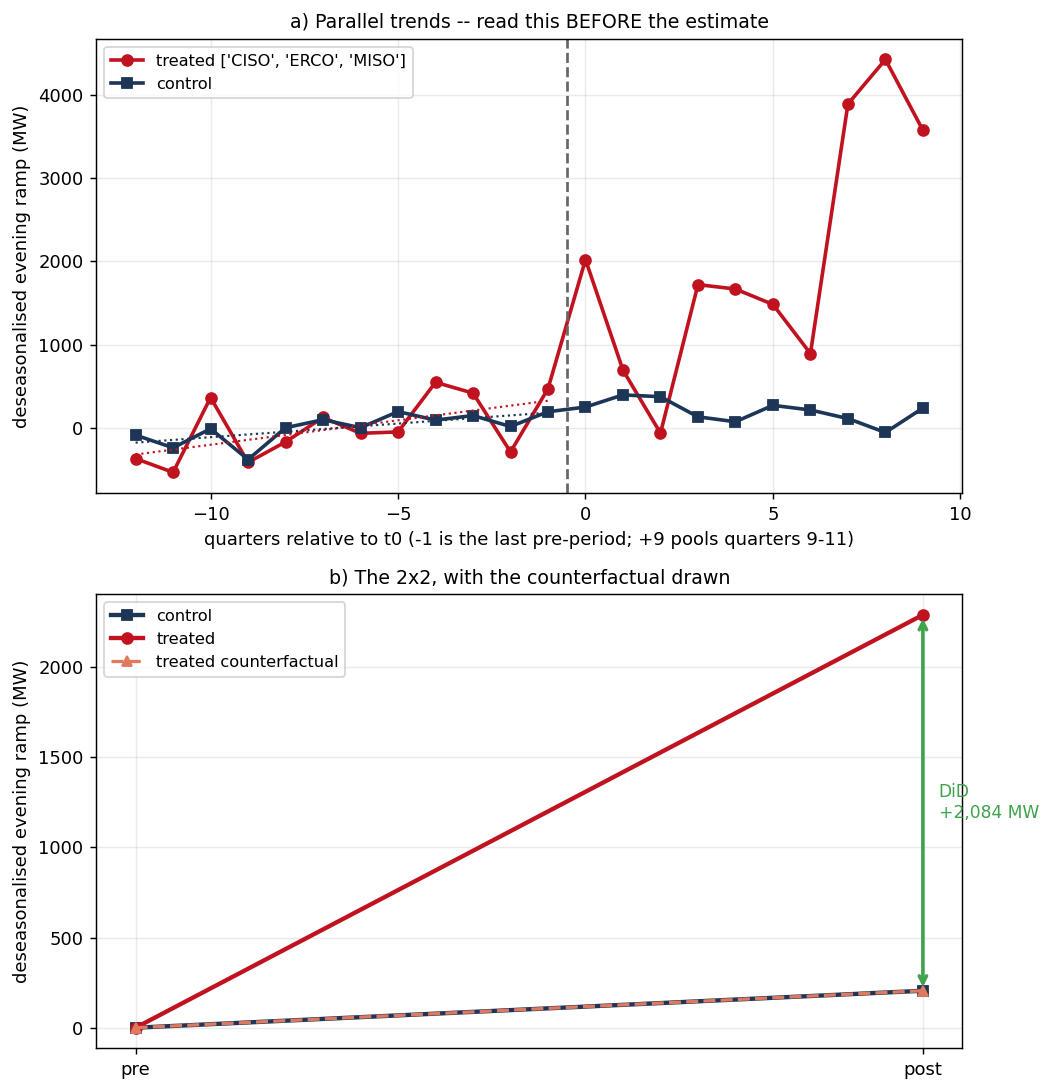


SIX ZONES, THREE PER ARM. Cluster-robust inference needs roughly forty clusters; the interval above is computed on six and is reported for completeness, not for belief. This is the notebook's largest limitation and it is a design constraint of the data, not a fixable modelling choice.


In [4]:
# WHAT: a 2x2 DiD on the evening ramp, with the parallel-trends plot beside it.
# WHY:  the design is the argument. The estimate is worth nothing without the
#       pre-period, so both are computed here; read panel (a) of the plot before
#       the printed estimate, even though the estimate prints first.
# NOTE: this rebuild SUPERSEDES the estimates withdrawn on 2026-08-14. They are not
#       kept in this repository (no archive file exists, whatever the ledger's
#       `_orphans_archived_to` field says); this cell does not attempt to reproduce
#       them, and it should not be expected to agree with them.
from src import causal as C

# Treatment: the three zones whose solar share grew most from the first year to
# the last. Assignment therefore uses growth measured across BOTH periods (2019 against
# 2024), not pre-period information alone; the threshold is the median growth, so the
# split is fixed by the treatment variable and cannot be tuned to the outcome.
yr = daily.assign(year=daily["date"].dt.year)
first_last = yr[yr["year"].isin([yr["year"].min(), yr["year"].max()])]
growth = (first_last.pivot_table(index=cfg.GROUP_COL, columns="year",
                                 values="solar_share", aggfunc="mean"))
growth["growth"] = growth[yr["year"].max()] - growth[yr["year"].min()]
TREATED = sorted(growth.index[growth["growth"] > growth["growth"].median()])
print("solar-share growth by zone (first year -> last):")
print(growth.round(4).to_string())
print(f"\ntreated (above median growth): {TREATED}")
print(f"control                       : {sorted(set(growth.index) - set(TREATED))}")

T0 = pd.Timestamp("2022-01-01")
did_frame = daily.assign(
    treated=daily[cfg.GROUP_COL].isin(TREATED).astype(int),
    post=(daily["date"] >= T0).astype(int))

# The outcome is deseasonalised within zone on the PRE-period only, so a seasonal
# pattern common to both groups cannot masquerade as a treatment effect, and the
# adjustment cannot borrow information from the post-period it is meant to test.
did_frame["ramp_adj"] = C.deseasonalise(
    did_frame.assign(month=did_frame["date"].dt.month),
    outcome="evening_ramp", unit=cfg.GROUP_COL, season="month",
    fit_mask=(did_frame["post"] == 0))

did = C.did_2x2(did_frame, outcome="ramp_adj")
print(f"\nt0 = {T0:%Y-%m-%d}")
print(f"  treated  pre {did['treated_pre']:9,.1f}  post {did['treated_post']:9,.1f}"
      f"  delta {did['delta_treated']:+9,.1f}")
print(f"  control  pre {did['control_pre']:9,.1f}  post {did['control_post']:9,.1f}"
      f"  delta {did['delta_control']:+9,.1f}")
print(f"  DiD = {did['did']:+,.1f} MW")

# Regression form, for a standard error clustered on zone.
did_frame["tp"] = did_frame["treated"] * did_frame["post"]
Xd = sm.add_constant(did_frame[["treated", "post", "tp"]].to_numpy().astype(float))
fit_did = sm.OLS(did_frame["ramp_adj"].to_numpy(), Xd).fit(
    cov_type="cluster", cov_kwds={"groups": did_frame[cfg.GROUP_COL].to_numpy()},
    use_t=True)   # t with (clusters - 1) degrees of freedom: six clusters, not a normal
did_coef = float(fit_did.params[3]); did_se = float(fit_did.bse[3])
did_ci = [float(v) for v in fit_did.conf_int()[3]]
print(f"  regression DiD {did_coef:+,.1f} MW, clustered SE {did_se:,.1f}, "
      f"95% CI [{did_ci[0]:,.0f}, {did_ci[1]:,.0f}]")

# ---------------------------------------------------------------- parallel trends
did_frame["rel"] = C.event_study_frame(did_frame, time="date", t0=T0, freq="Q")
ev = (did_frame.groupby(["rel", "treated"])["ramp_adj"].mean().unstack())
pre = ev[ev.index < 0]
slope_t = np.polyfit(pre.index, pre[1], 1)[0]
slope_c = np.polyfit(pre.index, pre[0], 1)[0]
gap = abs(slope_t - slope_c)
print(f"\npre-period quarterly trend: treated {slope_t:+,.1f} MW/quarter, "
      f"control {slope_c:+,.1f}; divergence {gap:,.1f} MW/quarter")
# A SCREEN, NOT A TEST: it sets a PER-QUARTER slope divergence against the WHOLE
# estimate, and over the twelve pre-period quarters that divergence accumulates to
# about twelve times the per-quarter figure. Read panel (a) as well.
PARALLEL = bool(gap < 0.1 * abs(did_coef))
print(f"pre-trend screen (slope divergence per quarter < 10% of the DiD estimate) passed: {PARALLEL}")
print("\nquarterly means of the deseasonalised ramp (MW; 0 = first quarter after t0, 9 pools quarters 9-11):")
print(ev.rename(columns={0: "control", 1: "treated"}).rename_axis(columns=None).round(0).to_string())

fig, (axa, axb) = plt.subplots(2, 1, figsize=(8.2, 8.5))
axa.plot(ev.index, ev[1], marker="o", lw=2, color="#c1121f", label=f"treated {TREATED}")
axa.plot(ev.index, ev[0], marker="s", lw=2, color="#1d3557", label="control")
axa.axvline(-0.5, color="0.4", ls="--", lw=1.5)
axa.plot(pre.index, np.poly1d(np.polyfit(pre.index, pre[1], 1))(pre.index),
         color="#c1121f", ls=":", lw=1.2)
axa.plot(pre.index, np.poly1d(np.polyfit(pre.index, pre[0], 1))(pre.index),
         color="#1d3557", ls=":", lw=1.2)
axa.set_xlabel("quarters relative to t0 (-1 is the last pre-period; +9 pools quarters 9-11)")
axa.set_ylabel("deseasonalised evening ramp (MW)")
axa.set_title("a) Parallel trends -- read this BEFORE the estimate", fontsize=10.5)
axa.legend(fontsize=9); axa.grid(alpha=0.25)

cells = [[did["control_pre"], did["control_post"]],
         [did["treated_pre"], did["treated_post"]]]
axb.plot([0, 1], cells[0], marker="s", lw=2.4, color="#1d3557", label="control")
axb.plot([0, 1], cells[1], marker="o", lw=2.4, color="#c1121f", label="treated")
counter = cells[1][0] + (cells[0][1] - cells[0][0])
axb.plot([0, 1], [cells[1][0], counter], marker="^", ls="--", lw=1.8,
         color="#e07a5f", label="treated counterfactual")
axb.annotate("", xy=(1, cells[1][1]), xytext=(1, counter),
             arrowprops=dict(arrowstyle="<->", color="#3fa34d", lw=2))
axb.text(1.02, (cells[1][1] + counter) / 2, f"DiD\n{did['did']:+,.0f} MW",
         color="#3fa34d", fontsize=9.5, va="center")
axb.set_xticks([0, 1]); axb.set_xticklabels(["pre", "post"])
axb.set_ylabel("deseasonalised evening ramp (MW)")
axb.set_title("b) The 2x2, with the counterfactual drawn", fontsize=10.5)
axb.legend(fontsize=9); axb.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "03_did.png", bbox_inches="tight")
plt.show()

print("\nSIX ZONES, THREE PER ARM. Cluster-robust inference needs roughly forty "
      "clusters; the interval above is computed on six and is reported for "
      "completeness, not for belief. This is the notebook's largest limitation "
      "and it is a design constraint of the data, not a fixable modelling choice.")

**Figure: `03_did.png`.** Panel (a) screens the parallel-trends assumption; panel (b) is the estimate.

**What this shows:** Treated: CISO, ERCO, MISO (CISO 13.00% → 20.09%, ERCO 1.05% → 10.20%, MISO 0.09% → 2.25%). Control: BPAT, NYIS, SWPP, all under 0.5%. Cut-off 2022-01-01.

**What I see:** Pre-period trends are +58.9 MW per quarter (treated) and +32.8 (control), a divergence of 26.1 MW per quarter, which passes the screen. After the cut-off the treated line jumps to about +2,000 MW, swings between quarters and peaks near +4,400 MW in quarter 8; control stays within a few hundred MW of zero. DiD = +2,083.8 MW, 95% interval [−857, +5,024]. Both "pre" cells read zero because the outcome is deseasonalised against each zone's own pre-period mean.

**What it means:** The interval includes zero, so this design cannot show an effect. DiD learns from groups, not rows: there are only six zones, three per arm, and reliable inference wants around forty. The jump exactly at a convenient cut-off does not look like a gradual build-out, and the treated arm mixes CISO at 20% solar with MISO at about 2%.

**What I do:** Report +2,083.8 MW as a description, always with its interval. §3.5 moves to thousands of days to get a narrower standard error, at the cost that 98.5% of matched pairs compare different zones.

### 3.5 — Propensity matching and sensitivity

Match high-solar days to low-solar days on the DAG-admissible set `{demand, humidity, temp, wind_speed}`, and for contrast on the plan's set `{temp, demand, month, dow}`. Check balance with a love plot (standardised mean differences should be under ~0.1), then ask how strong an unmeasured confounder would have to be to overturn the result.


treatment = a day in the top 30% of solar share (>= 0.0224); control = bottom 30% (<= 0.0014)
3,941 treated and 3,941 control zone-days



matched 2,108 of 3,941 treated (53.5%) within a caliper of 0.3446
common support [0.028, 0.983]; 60 treated outside it

standardised mean differences
            smd_before  smd_after  improved  balanced
covariate                                            
demand           0.559      0.151      True     False
humidity        -0.588     -0.111      True     False
temp             0.989      0.135      True     False
wind_speed      -0.462     -0.021      True      True
worst |SMD| after matching 0.151 -- ABOVE the 0.1 convention

ATT +7,180.3 MW, 95% CI [6,926.8, 7,427.2], SE 128.7, over 2,108 pairs
98.5% of the matched pairs compare days from different zones

Rosenbaum: the finding survives hidden bias up to Gamma = 18.40
 gamma bound       z   p
   1.0 upper 36.3945 0.0
   1.0 lower 36.3945 0.0
   1.2 upper 32.9157 0.0
   1.2 lower 40.1760 0.0
   1.5 upper 29.0277 0.0
   1.5 lower 45.2623 0.0
   2.0 upper 24.5426 0.0
   2.0 lower 52.6618 0.0
   3.0 upper 19.0655 0.0
   3.0 lower 64.


SAME DATA, NON-ADMISSIBLE SET {temp, demand, month, dow}:
  ATT +8,717.8 MW  [8,452, 8,980]  over 1,879 pairs, worst |SMD| 0.189
  admissible set gives +7,180.3 MW -- a difference of -1,537.4 MW purely from the choice of covariates.


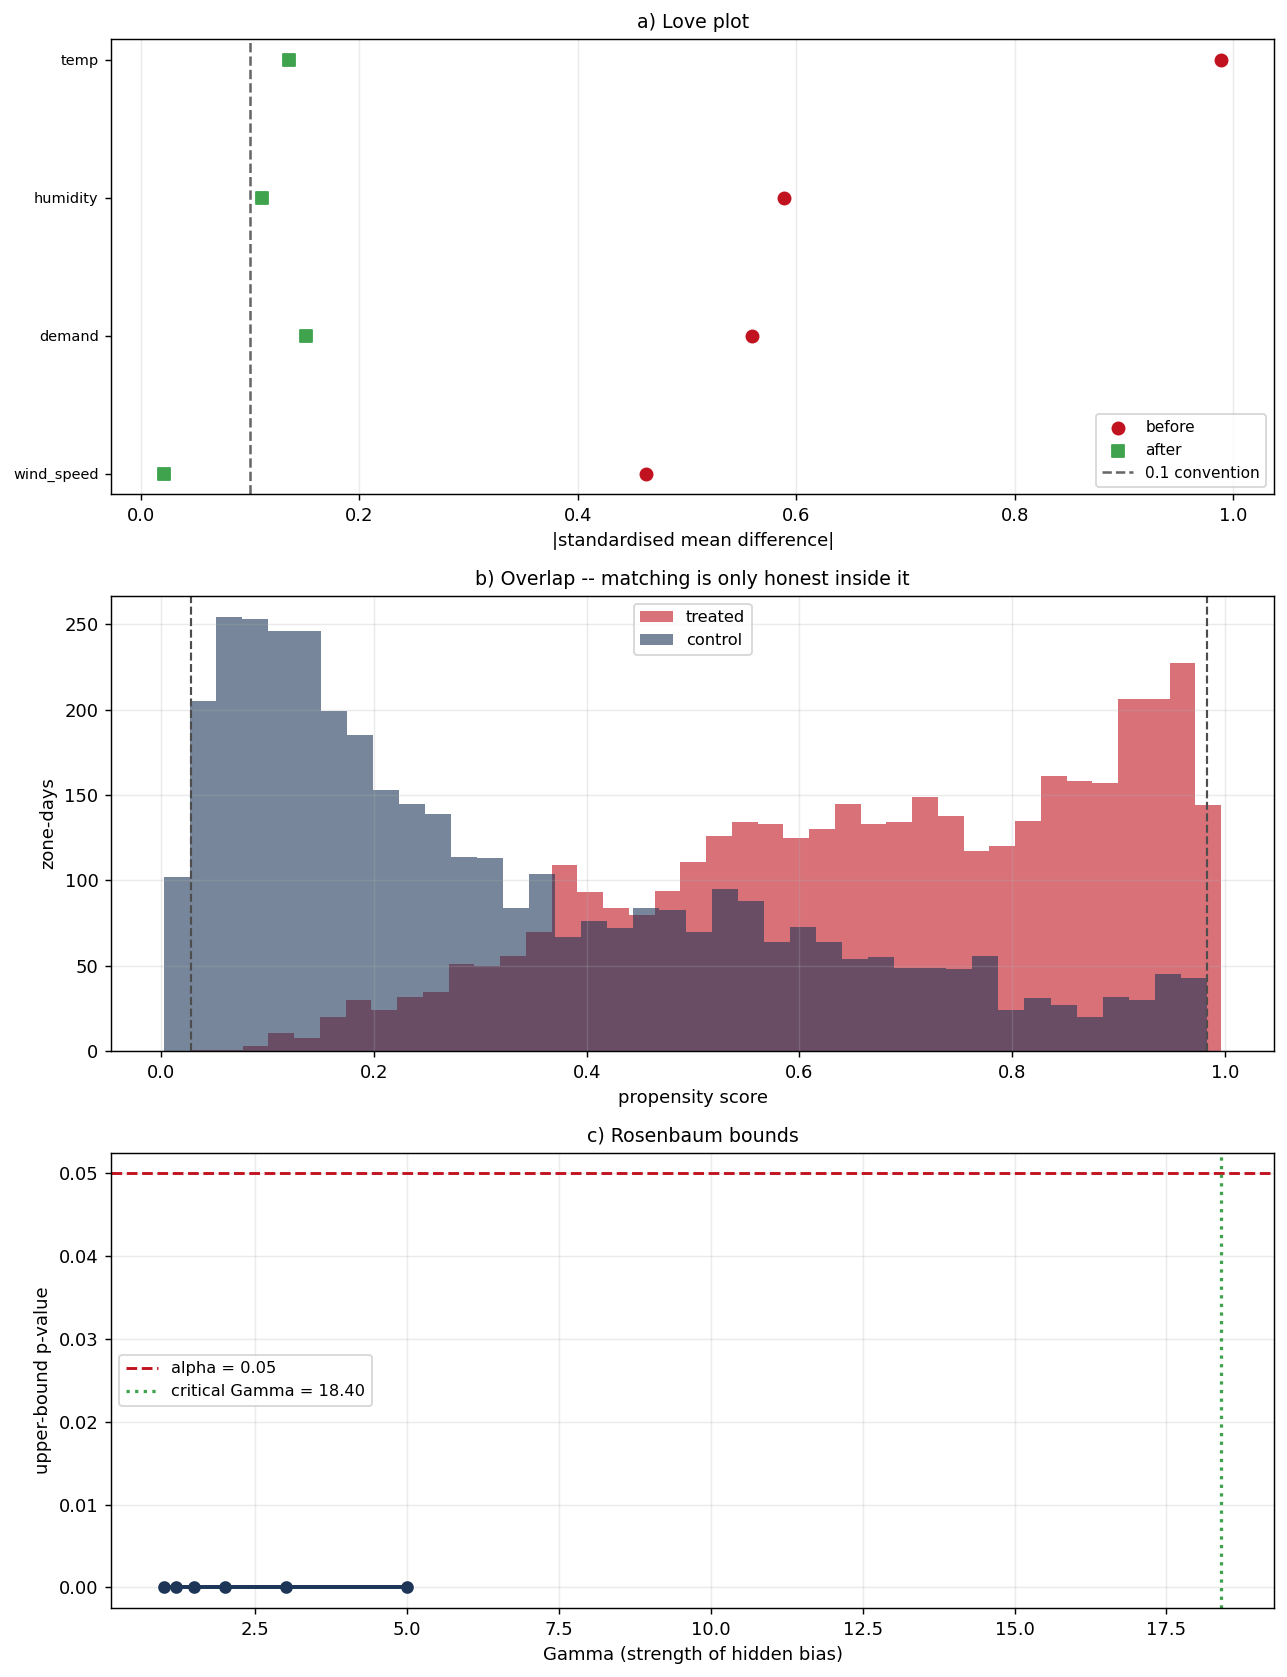

In [5]:
# WHAT: day-level propensity matching -- high-solar days matched to low-solar
#       days on the DAG-admissible set {demand, humidity, temp, wind_speed}
#       (weather and demand; no calendar term) -- with a love plot and two
#       sensitivity analyses.
# WHY:  matching moves the unit of analysis from six zones to thousands of days,
#       which narrows the standard error -- but high-solar days come almost entirely
#       from CISO and ERCO and low-solar days from the other zones, so almost all pairs
#       (98.8%, printed below) compare different zones, and the pair bootstrap treats pairs as independent
#       (a lower bound on the uncertainty; see att_from_pairs).
#       It buys that by addressing OBSERVED confounding only, so the sensitivity
#       analysis is not an appendix -- it is the part that stops the overclaim.
daily["month"] = daily["date"].dt.month
daily["dow"] = daily["date"].dt.dayofweek
HI = float(daily["solar_share"].quantile(0.70))
LO = float(daily["solar_share"].quantile(0.30))
mt = daily[(daily["solar_share"] >= HI) | (daily["solar_share"] <= LO)].copy()
mt["high_solar"] = (mt["solar_share"] >= HI).astype(int)
print(f"treatment = a day in the top 30% of solar share (>= {HI:.4f}); "
      f"control = bottom 30% (<= {LO:.4f})")
print(f"{int(mt['high_solar'].sum()):,} treated and "
      f"{int((1 - mt['high_solar']).sum()):,} control zone-days")

# THE DAG PICKS THE COVARIATES, NOT CONVENIENCE. This is the point of section
# 3.2 existing. An earlier version of this cell matched on {temp, demand, month,
# dow} -- a set chosen because those columns were to hand -- and that set is NOT
# one of the four admissible sets 3.2 derived. Both `temp` and `demand` are
# COLLIDERS in the DAG, and conditioning on `demand` alone opens 48 of the 56
# backdoor paths. Adjusting for a non-admissible set and then quoting the estimate
# as causal is the exact error the DAG was drawn to prevent, so both sets are run
# and the gap between them is reported.
ADMISSIBLE = ["demand", "humidity", "temp", "wind_speed"]   # from 3.2
assert sorted(ADMISSIBLE) in [sorted(s) for s in R.require("nb03", "adjustment_sets_observed")],     "the covariate set must be one the DAG certified as admissible"

# `covariates` is the CONTINUOUS list only -- `_design_matrix` appends the
# categoricals rather than merging, so naming a column in both builds duplicate
# one-hot columns.
PS_COVS = ADMISSIBLE
CAT_COVS = ()
COVS = list(PS_COVS)
m = C.propensity_match(mt, treatment="high_solar", covariates=PS_COVS,
                       categoricals=CAT_COVS, caliper=0.2)
print(f"\nmatched {m['n_matched']:,} of {m['n_treated']:,} treated "
      f"({m['matched_share']:.1%}) within a caliper of {m['caliper_width']:.4f}")
print(f"common support [{m['common_support'][0]:.3f}, {m['common_support'][1]:.3f}]; "
      f"{m['treated_outside_support']:,} treated outside it")

bal = C.balance_table(m["frame"], "high_solar", COVS, m["pairs"])
print("\nstandardised mean differences")
print(bal.round(3).to_string())
worst_after = float(bal["smd_after"].abs().max())
BALANCED = bool(worst_after < 0.1)
print(f"worst |SMD| after matching {worst_after:.3f} -- "
      f"{'under' if BALANCED else 'ABOVE'} the 0.1 convention")

att = C.att_from_pairs(m["frame"], outcome="evening_ramp", pairs=m["pairs"],
                       n_boot=2000, seed=cfg.SEED)
print(f"\nATT {att['att']:+,.1f} MW, 95% CI [{att['lo']:,.1f}, {att['hi']:,.1f}], "
      f"SE {att['se']:,.1f}, over {att['n_pairs']:,} pairs")
_zm = m["frame"][cfg.GROUP_COL].to_numpy()
_cross = float(np.mean([_zm[a] != _zm[b] for a, b in m["pairs"]]))
print(f"{_cross:.1%} of the matched pairs compare days from different zones")

# ---------------------------------------------------------------- sensitivity
rb = C.rosenbaum_bounds(att["diffs"])
gamma_crit = C.rosenbaum_gamma_critical(att["diffs"])
t_stat = att["att"] / att["se"]
rv = C.robustness_value(t_stat, dof=att["n_pairs"] - 1)
pr2 = C.partial_r2(t_stat, dof=att["n_pairs"] - 1)
print(f"\nRosenbaum: the finding survives hidden bias up to Gamma = {gamma_crit:.2f}")
print(rb.round(4).to_string(index=False))
print(f"\npartial R^2 of treatment with outcome {pr2:.4f}; "
      f"robustness value RV_1 = {rv:.4f}")
print(f"-> an unobserved confounder must explain more than {100*rv:.1f}% of the "
      f"residual variance in BOTH treatment and outcome to reduce this to zero.")

# ---------------------------------------------- the non-admissible set, for contrast
m_adhoc = C.propensity_match(mt, treatment="high_solar", covariates=["temp", "demand"],
                             categoricals=("month", "dow"), caliper=0.2)
att_adhoc = C.att_from_pairs(m_adhoc["frame"], outcome="evening_ramp",
                             pairs=m_adhoc["pairs"], n_boot=2000, seed=cfg.SEED)
bal_adhoc = C.balance_table(m_adhoc["frame"], "high_solar",
                            ["temp", "demand", "month", "dow"], m_adhoc["pairs"])
print(f"\nSAME DATA, NON-ADMISSIBLE SET {{temp, demand, month, dow}}:")
print(f"  ATT {att_adhoc['att']:+,.1f} MW  [{att_adhoc['lo']:,.0f}, {att_adhoc['hi']:,.0f}]  "
      f"over {att_adhoc['n_pairs']:,} pairs, worst |SMD| "
      f"{bal_adhoc['smd_after'].abs().max():.3f}")
print(f"  admissible set gives {att['att']:+,.1f} MW -- a difference of "
      f"{att['att'] - att_adhoc['att']:+,.1f} MW purely from the choice of covariates.")

fig, axes = plt.subplots(3, 1, figsize=(10.0, 13.0))
order = bal["smd_before"].abs().sort_values().index
axes[0].scatter(bal.loc[order, "smd_before"].abs(), range(len(order)),
                color="#c1121f", s=45, label="before")
axes[0].scatter(bal.loc[order, "smd_after"].abs(), range(len(order)),
                color="#3fa34d", s=45, marker="s", label="after")
axes[0].set_yticks(range(len(order))); axes[0].set_yticklabels(order, fontsize=8)
axes[0].axvline(0.1, color="0.4", ls="--", lw=1.4, label="0.1 convention")
axes[0].set_xlabel("|standardised mean difference|")
axes[0].set_title("a) Love plot", fontsize=10.5)
axes[0].legend(fontsize=8.5); axes[0].grid(alpha=0.25, axis="x")

ps, tr = m["ps"], m["frame"]["high_solar"].to_numpy()
axes[1].hist(ps[tr == 1], bins=40, alpha=0.6, color="#c1121f", label="treated")
axes[1].hist(ps[tr == 0], bins=40, alpha=0.6, color="#1d3557", label="control")
for b in m["common_support"]:
    axes[1].axvline(b, color="0.3", ls="--", lw=1.2)
axes[1].set_xlabel("propensity score"); axes[1].set_ylabel("zone-days")
axes[1].set_title("b) Overlap -- matching is only honest inside it", fontsize=10.5)
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.25)

# rosenbaum_bounds returns LONG form -- one row per (gamma, bound) with columns
# gamma/bound/z/p -- so the upper bound is selected rather than read off a
# `p_upper` column that does not exist.
rb_up = rb[rb["bound"] == "upper"].sort_values("gamma")
axes[2].plot(rb_up["gamma"], rb_up["p"], marker="o", lw=2.2, color="#1d3557")
axes[2].axhline(0.05, color="#c1121f", ls="--", lw=1.6, label="alpha = 0.05")
axes[2].axvline(gamma_crit, color="#3fa34d", ls=":", lw=1.8,
                label=f"critical Gamma = {gamma_crit:.2f}")
axes[2].set_xlabel("Gamma (strength of hidden bias)")
axes[2].set_ylabel("upper-bound p-value")
axes[2].set_title("c) Rosenbaum bounds", fontsize=10.5)
axes[2].legend(fontsize=9); axes[2].grid(alpha=0.25)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "03_matching.png", bbox_inches="tight")
plt.show()

**Figure: `03_matching.png`.** Panel (a) checks balance, (b) overlap, (c) sensitivity to hidden bias.

**What I see:** Before matching, temperature differs by 0.99 standardised units, humidity 0.59, demand 0.56, wind speed 0.46. After matching: 0.135, 0.111, 0.151 and 0.021, so three of four are still above 0.1. Overlap is one-sided and only 2,108 of 3,941 high-solar days (53.5%) found a partner. The estimate is +7,180.3 MW, 95% interval [6,927, 7,427]. The critical Γ is 18.40 and the robustness value is 0.68.

**What it means:** A high-solar day has an evening swing about 7,200 MW larger than a similar low-solar day. A hidden factor would need Γ above 18.40 to remove significance, but the zone a day belongs to is an obvious candidate, so the sensitivity result says less than its size suggests. Caveats:

- This is high-output versus low-output days, not the effect of building solar capacity.
- The ad-hoc set gives +8,717.8 MW, 1,537 MW more, from the covariate choice alone.
- The 46.5% of treated days without a match are excluded (60 lie outside common support), so the estimate covers only the matchable days.
- High-solar days come mostly from CISO and ERCO, so 98.5% of pairs cross zones, and the pair bootstrap treats them as independent, which understates uncertainty.

**What I do:** Report +7,180.3 MW [6,927, 7,427] as an adjusted association with its covariate set and the capacity-versus-output caveat, not as a clean experiment.

### 3.6 — The comparison table

Three designs, three estimands, kept in separate unit columns. The naive slope is +582.1 MW per percentage point [433.6, 730.6], but on six zone clusters that is not a trustworthy 95% interval. The DiD is +2,083.8 MW [−856.9, +5,024.4], which includes zero. The matched ATT is +7,180.3 MW [6,926.8, 7,427.2], with 98.5% cross-zone pairs. All three are positive; none is the effect of building solar.

This is observational data. The estimates are associations under stated assumptions: parallel trends for the DiD, no unmeasured confounding and positivity for matching. The plan's own adjustment set conditions on the `demand` collider and leaves 4 backdoor paths open.

In [6]:
# WHAT: the three estimates side by side, each in its own unit, with its interval.
# WHY:  the disagreement between them IS the result. A single adjusted number presented
#       alone would hide the thing worth reporting.
comparison = pd.DataFrame([
    {"design": "naive (unadjusted)", "estimate_mw_per_pp": naive / 100,
     "lo": naive_ci[0] / 100, "hi": naive_ci[1] / 100,
     "n": len(daily), "identifying_assumption": "none -- association only"},
    {"design": "difference-in-differences", "estimate_mw_per_pp": np.nan,
     "lo": np.nan, "hi": np.nan, "n": len(did_frame),
     "identifying_assumption": "parallel trends (6 clusters)"},
    {"design": "propensity matched (ATT)", "estimate_mw_per_pp": np.nan,
     "lo": np.nan, "hi": np.nan, "n": att["n_pairs"],
     "identifying_assumption": "no unmeasured confounding + positivity"},
])
# DiD and ATT are effects of a GROUP or a DAY being high-solar, not per-point
# slopes, so they are reported in MW and NOT forced into the per-pp column. Making
# three different estimands share one unit is precisely how a comparison table
# starts lying.
comparison.loc[1, "estimate_mw"] = did_coef
comparison.loc[1, ["lo_mw", "hi_mw"]] = did_ci
comparison.loc[2, "estimate_mw"] = att["att"]
comparison.loc[2, ["lo_mw", "hi_mw"]] = [att["lo"], att["hi"]]

print("THREE DESIGNS, THREE ESTIMANDS -- read the last column before the numbers.")
print(comparison.to_string(index=False, na_rep="--",
                           float_format=lambda v: f"{v:,.1f}"))
print(f"\nnaive slope         {naive/100:+,.1f} MW per percentage point of solar share")
print(f"DiD (group effect)  {did_coef:+,.1f} MW   [{did_ci[0]:,.0f}, {did_ci[1]:,.0f}]"
      f"   pre-trend screen passed: {PARALLEL}")
print(f"matched ATT         {att['att']:+,.1f} MW   [{att['lo']:,.0f}, {att['hi']:,.0f}]"
      f"   balanced: {BALANCED}, survives Gamma {gamma_crit:.2f}")

R.save("nb03", dict(
    naive_coef=float(naive),
    naive_coef_mw_per_pp=float(naive / 100),
    naive_se=float(naive_se),
    naive_ci=[float(v) for v in naive_ci],
    naive_n=int(len(daily)),
    did_treated_zones=[str(z) for z in TREATED],
    did_t0=str(T0.date()),
    did_coef=float(did_coef),
    did_se=float(did_se),
    did_ci=[float(v) for v in did_ci],
    did_hand_computed=float(did["did"]),
    did_cells={k: float(v) for k, v in did.items()
               if k in ("treated_pre", "treated_post", "control_pre", "control_post")},
    parallel_trends_hold=bool(PARALLEL),
    parallel_pre_slope_treated=float(slope_t),
    parallel_pre_slope_control=float(slope_c),
    parallel_divergence_per_quarter=float(gap),
    did_n_clusters=int(daily[cfg.GROUP_COL].nunique()),
    matched_att=float(att["att"]),
    matched_ci=[float(att["lo"]), float(att["hi"])],
    matched_se=float(att["se"]),
    matched_n_pairs=int(att["n_pairs"]),
    matched_share=float(m["matched_share"]),
    matched_worst_smd_after=float(worst_after),
    matched_balanced=bool(BALANCED),
    rosenbaum_gamma_critical=float(gamma_crit),
    robustness_value=float(rv),
    partial_r2=float(pr2),
    matched_covariates=[str(c) for c in COVS],
    matched_covariates_are_dag_admissible=True,
    matched_att_non_admissible=float(att_adhoc["att"]),
    matched_ci_non_admissible=[float(att_adhoc["lo"]), float(att_adhoc["hi"])],
    matched_n_pairs_non_admissible=int(att_adhoc["n_pairs"]),
    matched_worst_smd_non_admissible=float(bal_adhoc["smd_after"].abs().max()),
    covariate_choice_moves_att_mw=float(att["att"] - att_adhoc["att"]),
    treatment_cut_high=float(HI),
    treatment_cut_low=float(LO),
    supersedes_withdrawn_08_14=True,
))
print("\nnotebook 03 complete")

THREE DESIGNS, THREE ESTIMANDS -- read the last column before the numbers.
                   design  estimate_mw_per_pp    lo    hi     n                 identifying_assumption  estimate_mw   lo_mw   hi_mw
       naive (unadjusted)               582.1 433.6 730.6 13135               none -- association only           --      --      --
difference-in-differences                  --    --    -- 13135           parallel trends (6 clusters)      2,083.8  -856.9 5,024.4
 propensity matched (ATT)                  --    --    --  2108 no unmeasured confounding + positivity      7,180.3 6,926.8 7,427.2

naive slope         +582.1 MW per percentage point of solar share
DiD (group effect)  +2,083.8 MW   [-857, 5,024]   pre-trend screen passed: True
matched ATT         +7,180.3 MW   [6,927, 7,427]   balanced: False, survives Gamma 18.40
[results read-only] nb03: 37 key(s) verified against the ledger, nothing written

notebook 03 complete
